# 1. Merge & Pre-processing
The cleaned transactions (`train`) and the cleaned customer table (`clientes`) are merged into one dataset, split into training and validation folds, and pre-processed in order: outliers, missing values, and encoding and scaling.

In [1]:
import warnings
from collections import namedtuple
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.experimental import enable_iterative_imputer  # noqa: F401 (needed for IterativeImputer)
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, RobustScaler, StandardScaler

# Same seed everywhere, so every run gives the same splits and draws
RANDOM_STATE = 42

____________________________________________________________________________________________________

## 1.1. Data Loading

In [2]:
trainFile = "../../data/trainDataset/train_2_5_1.csv"
clientFile = "../../data/clientesDataset/clientes_clean.csv"
testFile = "../../data/test.csv"

train = pd.read_csv(trainFile)
clientes = pd.read_csv(clientFile)
test = pd.read_csv(testFile)

RANDOM_STATE= 42

____________________________________________________________________________________________________

## 1.2. Merging the Datasets

In [3]:
train_clientes = train.merge(clientes, on="customer_id", how="left", validate="many_to_one")
assert len(train_clientes) == len(train)

train_clientes.head()

,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,island,municipality,city,postal_area,postal_code,street,address,company_name,customer_since_year,since_2015_or_earlier
0,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,...,(mainland),Municipality MU89: Council of Last Minute Edits,City CY286: Cached Result Falls,Postal area PA228: Hidden Sheet Sector,Postal code PC444: #REF! Delivery Route,Street ST303: Absolute Reference Terrace,Address AD761: Cell Without a Home,Excel Is Not A Database Ltd 1013,2024,0
1,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,...,Island IS8: The Pivot Archipelago,Municipality MU11: Council of Last Minute Edits,City CY147: VLOOKUP Bay,Postal area PA260: Hidden Sheet Sector,Postal code PC636: #REF! Delivery Route,NaN,Address AD382: Cell Without a Home,Excel Is Not A Database Ltd 35,2015,1
2,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,...,(mainland),Municipality MU70: Council of Last Minute Edits,City CY265: Where-less Query Falls,Postal area PA84: Hidden Sheet Sector,Postal code PC200: #REF! Delivery Route,NaN,Address AD723: Cell Without a Home,Excel Is Not A Database Ltd 826,2017,0
3,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,...,Island IS7: The Pivot Archipelago,Municipality MU12: Council of Last Minute Edits,NaN,Postal area PA253: Hidden Sheet Sector,Postal code PC558: #REF! Delivery Route,Street ST144: Last Save Court,Address AD399: Cell Without a Home,Excel Is Not A Database Ltd 530,2018,0
4,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,...,(mainland),Municipality MU142: Council of Last Minute Edits,City CY359: Spill Error Ridge,Postal area PA136: Hidden Sheet Sector,Postal code PC300: #REF! Delivery Route,Street ST395: AutoFill Path,Address AD928: Cell Without a Home,Excel Is Not A Database Ltd 220,2017,0


**Conclusions:**
* **Lossless merge:** every one of the **6,469** transactions found its customer (`validate="many_to_one"` confirms one row per `customer_id` in `clientes`), so no rows were lost or duplicated. The merged table has **57 columns**: the 45 of `train` plus 12 customer attributes.
* **Customer coverage:** the transactions belong to **607** customers, so 536 of the 1,143 customers in `clientes` have no purchase in `train` and are simply not used.
* **New missing values:** the customer attributes bring their own gaps into the merged table, mostly in identifier-like columns: `street` (58.9%), `city` (32.9%) and `postal_code` (3.4%). The descriptive ones are almost complete: `postal_area` (1.0%), `commercial_region` (0.5%), `island` and `municipality` (0.1%). These are handled together with the `train` gaps in the next sections.

____________________________________________________________________________________________________

## 1.3. Feature Type Separation
Imputation and encoding work differently on numbers and on labels (a median or a KNN fill needs numbers, a mode or an `"Unknown"` level works on labels), so the merged columns are split into groups first:

1. **Target:** `repeat_purchase_90d`, the variable to predict.
2. **Identifiers:** `ID` (one per row) and `customer_id` (the join key, kept to group the cross-validation folds by customer).
3. **Excluded:** `company_name`, `address`, `street` and `postal_code` are distinct for almost every customer, so they name a customer instead of describing one; `random_noise` carries no information by construction.
4. **Numeric** and **categorical** features: everything else, separated by data type.

In [4]:
target = "repeat_purchase_90d"
identifiers = ["ID", "customer_id"]

# Unique per customer (they name a customer instead of describing one) or pure noise
excluded = ["company_name", "address", "street", "postal_code", "random_noise"]

features = [c for c in train_clientes.columns if c not in [target] + identifiers + excluded]

# Automatic separation between numerical and categorical variables
numeric = [c for c in features if pd.api.types.is_numeric_dtype(train_clientes[c])]
categorical = [c for c in features if c not in numeric]

# Every column belongs to exactly one group
assert set([target] + identifiers + excluded + numeric + categorical) == set(train_clientes.columns)

features = train_clientes[numeric + categorical]
identifier = train_clientes[target]

print(f"{len(numeric)} numeric | {len(categorical)} categorical | {len(identifiers)} identifiers | {len(excluded)} excluded")
print("categorical:", categorical)

37 numeric | 12 categorical | 2 identifiers | 5 excluded
categorical: ['payment_type', 'salesperson', 'commercial_zone', 'transport_method', 'warehouse', 'document_series', 'country_or_region', 'commercial_region', 'island', 'municipality', 'city', 'postal_area']


**Conclusions:**
* **49 features** are left for the model: **37 numeric** and **12 categorical**. The target has no missing values and is fairly balanced (56% of purchases are repeated within 90 days).
* **Numbers that are labels:** some numeric columns are categories written as numbers: `purchase_month`, `purchase_dayofweek`, `purchase_quarter` and the 0/1 flags `is_first_purchase`, `is_weekend` and `since_2015_or_earlier`. None of them has missing values, so they do not affect the imputation; whether they are encoded as categories is decided in the encoding step.

____________________________________________________________________________________________________

## 1.4. Missing Values Overview

In this step, we measure the missing values, which gave us some information about which features still have gaps after the merge, how many, and whether if a value is missing says something about the target.

In [5]:
# Which features still have missing values, and in which group
missing = features.isna().sum()
overview = pd.DataFrame({
    "group": ["numeric" if c in numeric else "categorical" for c in features.columns],
    "n_missing": missing,
    "pct_missing": (missing / len(features) * 100).round(1),
    # Repeat rate among rows where the value is missing, against rows where it is present
    "target_if_missing": [identifier[features[c].isna()].mean() for c in features.columns],
    "target_if_present": [identifier[features[c].notna()].mean() for c in features.columns],
}).query("n_missing > 0").sort_values("n_missing", ascending=False).round(3)

print(f"rows with at least one missing value: {features.isna().any(axis=1).sum():,} of {len(features):,}")
overview

rows with at least one missing value: 2,823 of 6,469


,group,n_missing,pct_missing,target_if_missing,target_if_present
city,categorical,2128,32.9,0.553,0.563
spend_365d,numeric,210,3.2,0.552,0.560
transport_method,categorical,196,3.0,0.551,0.560
payment_type,categorical,195,3.0,0.564,0.560
warehouse,categorical,195,3.0,0.636,0.557
salesperson,categorical,194,3.0,0.598,0.559
postal_area,categorical,65,1.0,0.492,0.560
commercial_region,categorical,35,0.5,0.343,0.561
municipality,categorical,4,0.1,0.000,0.560
island,categorical,4,0.1,0.000,0.560


**Conclusions:**

____________________________________________________________________________________________________

## 1.5. Train / Validation Split

### 1.5.1. Evaluation Setup
Every comparison below runs through the same three tools, written once, as in the course practical: the **model matrix** (`design_matrix`), the **fill** that makes a split ready for a model (`fill_missing`), and the **scorer** (`held_out_scores`), which trains a logistic regression on the training rows of each split and scores it on the untouched validation rows.

The scorer returns two measures. **Average precision (AP)** decides every comparison: it reads the predicted probabilities and asks whether the customers who come back are ranked above the ones who do not, without choosing a cut-off. **F1**, the competition metric, is shown beside it; it depends on cutting the probabilities at 0.5, which section 1.5.3 shows is fragile. The cut-off is chosen, and F1 reported, for the final model.

In [6]:
# The table every comparison works on: the features plus the target
frame = features.join(identifier)

# Logistic regression may stop before converging on unscaled columns; scaling is compared in 1.8
warnings.filterwarnings("ignore", category=ConvergenceWarning)


def design_matrix(frame, numeric, categorical):
    """Numbers as they are, everything else one-hot. Identifiers never enter."""
    encoder = OneHotEncoder(sparse_output=False, dtype=float)
    encoded = encoder.fit_transform(frame[categorical].astype("string"))
    text = pd.DataFrame(
        encoded,
        columns=encoder.get_feature_names_out(categorical),
        index=frame.index,
    )
    return pd.concat([frame[numeric], text], axis=1)


def fill_missing(train, test, plan):
    """Fill every missing value with imputers fitted on `train` alone.

    `plan` is a list of (columns, imputer) pairs: each imputer is fitted on the
    training rows of its own columns and fills those columns in both halves, so
    the validation rows never help compute a fill.
    """
    train, test = train.copy(), test.copy()
    for columns, imputer in plan:
        # scikit-learn reads np.nan as a gap but not pd.NA, so every gap becomes np.nan
        blocks = [half[columns].astype(object).fillna(np.nan).infer_objects()
                  for half in (train, test)]
        if isinstance(imputer, (KNNImputer, IterativeImputer)):
            # Both are sensitive to scale, so they work on standardised columns
            # and their fills go back in the columns' own units
            scale = StandardScaler().fit(blocks[0])
            imputer.fit(scale.transform(blocks[0]))
            filled = [scale.inverse_transform(imputer.transform(scale.transform(block)))
                      for block in blocks]
        else:
            imputer.fit(blocks[0])
            filled = [imputer.transform(block) for block in blocks]
        train[columns], test[columns] = filled
    return train, test


# A model cannot fit a missing value, so every comparison fills inside its own split.
# Until section 1.6 chooses a plan, that fill is the training median for the numbers
# and the training mode for the labels.
median_mode = [(numeric, SimpleImputer(strategy="median")),
               (categorical, SimpleImputer(strategy="most_frequent"))]

Scored = namedtuple("Scored", "ap f1 iterations predictions")


def sem(values):
    """Standard error of the mean: how far it would move on new splits."""
    return values.std(ddof=1) / np.sqrt(len(values))


def held_out_scores(prepare, frame, splits, numeric, categorical,
                    target="repeat_purchase_90d", scaler=None):
    """Score one treatment on each split's untouched validation rows.

    `prepare(train, test)` applies the treatment, fitted on `train` only. The
    result holds, per split, the validation average precision (`.ap`), the F1
    at the 0.5 cut-off (`.f1`), the solver's iterations (`.iterations`) and the
    (true labels, predicted probabilities) pair (`.predictions`). `scaler`, when
    given, is fitted on the training rows and applied to both.
    """
    ap, f1, iterations, predictions = [], [], [], []
    for train_rows, test_rows in splits:
        train, test = prepare(frame.iloc[train_rows], frame.iloc[test_rows])
        matrix = design_matrix(pd.concat([train, test]), numeric, categorical)
        a, b = matrix.iloc[:len(train)], matrix.iloc[len(train):]
        if scaler is not None:
            fitted = scaler.fit(a)
            a, b = fitted.transform(a), fitted.transform(b)
        model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
        model.fit(a, train[target])
        probabilities = model.predict_proba(b)[:, 1]
        ap.append(average_precision_score(test[target], probabilities))
        f1.append(f1_score(test[target], probabilities >= 0.5))
        iterations.append(int(model.n_iter_[0]))
        predictions.append((test[target].to_numpy(), probabilities))
    return Scored(np.array(ap), np.array(f1), np.array(iterations), predictions)

### 1.5.2. Temporal Splits
The course practical (`week_03_deepen_exploration`) scores every candidate on 20 **random** splits. That works for its data, which has no dates, but here a random split would leak the future:

* **The target looks ahead.** `repeat_purchase_90d` is 1 when the same customer buys again within 90 days, so the label of one purchase depends on the customer's *next* purchase. A random split can put that next purchase in training while it scores the earlier one, and the same customer's purchases on both sides look alike.
* **The test is later in time.** `test.csv` covers May 2025 to October 2026, after every purchase in `train`, and the repeat rate rises over the years. A random split hides that drift, and the competition rules penalise a large gap between the performance a notebook reports and its Kaggle result.

So every comparison in sections 1.6 to 1.8, and the final model's reported performance, uses splits **in time**: each one trains on the past and validates on the period after it. The rest of the practical's method stays: every step that learns from the data is fitted on the training rows of each split only, rows are never dropped from the validation side, and every candidate is scored on the same validation rows.

* **Rolling origin:** the rows are ordered by purchase date and cut into 10 consecutive blocks with `TimeSeriesSplit`; each block is validated by a model trained only on the purchases before it.
* **Enough history:** the first blocks have very few purchases before them, so a block is kept only when its training side has at least 2,000 rows.
* **90-day gap:** the training purchases from the 90 days before each validation block are left out, because their labels depend on purchases inside the block. A similar gap separates `train` from `test.csv` (98 days).
* **Same scorer:** `held_out_scores` accepts any list of (training rows, validation rows) pairs, so these splits use it unchanged.

In [7]:
# Purchase date, rebuilt from its parts (train_2_5_1 no longer carries purchase_date)
purchase_dates = pd.to_datetime(frame[["purchase_year", "purchase_month", "purchase_day"]]
                                .set_axis(["year", "month", "day"], axis=1))

# Positions of the rows in date order; TimeSeriesSplit cuts this order into blocks
order = np.argsort(purchase_dates.to_numpy(), kind="stable")
GAP = pd.Timedelta(days=90)
MIN_TRAIN = 2000

time_splits = []
for train_block, validation_block in TimeSeriesSplit(n_splits=10).split(order):
    train_rows, validation_rows = order[train_block], order[validation_block]
    # Leave out the training purchases whose 90-day window reaches the validation block
    start = purchase_dates.iloc[validation_rows].min()
    train_rows = train_rows[(purchase_dates.iloc[train_rows] < start - GAP).to_numpy()]
    # The first blocks have too little history to train on
    if len(train_rows) >= MIN_TRAIN:
        time_splits.append((train_rows, validation_rows))

print(f"{len(time_splits)} temporal splits kept of 10")

7 temporal splits kept of 10


In [8]:
# Check: each split trains on the past only and validates on the period after it
pd.DataFrame([{"training until": purchase_dates.iloc[tr].max().date(),
               "validation from": purchase_dates.iloc[va].min().date(),
               "validation until": purchase_dates.iloc[va].max().date(),
               "training rows": len(tr), "validation rows": len(va),
               "training rate": identifier.iloc[tr].mean(),
               "validation rate": identifier.iloc[va].mean()}
              for tr, va in time_splits]).round(3)

,training until,validation from,validation until,training rows,validation rows,training rate,validation rate
0,2019-03-10,2019-06-09,2020-03-28,2229,588,0.563,0.563
1,2019-12-28,2020-03-28,2021-03-06,2785,588,0.553,0.604
2,2020-12-05,2021-03-06,2021-11-13,3399,588,0.562,0.537
3,2021-08-14,2021-11-13,2022-10-02,3898,588,0.562,0.502
4,2022-07-05,2022-10-04,2023-07-28,4524,588,0.558,0.502
5,2023-04-29,2023-07-29,2024-04-13,5131,588,0.548,0.622
6,2024-01-13,2024-04-13,2025-02-15,5665,588,0.554,0.605


In [9]:
# The baseline every later section has to beat, on the temporal splits
time_baseline = held_out_scores(partial(fill_missing, plan=median_mode),
                                frame, time_splits, numeric, categorical)

# Predicting a repeat purchase for every customer, the floor any model must clear.
# A constant score ranks nobody, so its AP is just the share of repeat purchases.
all_positive_f1 = np.array([f1_score(identifier.iloc[va], np.ones(len(va))) for _, va in time_splits])
all_positive_ap = np.array([identifier.iloc[va].mean() for _, va in time_splits])

print(f"temporal baseline    AP {time_baseline.ap.mean():.4f} +/- {sem(time_baseline.ap):.4f}"
      f"   F1 {time_baseline.f1.mean():.4f} +/- {sem(time_baseline.f1):.4f}")
print(f"predict-all-positive AP {all_positive_ap.mean():.4f}             F1 {all_positive_f1.mean():.4f}")
print(f"AP per split {np.round(time_baseline.ap, 4)}")

temporal baseline    AP 0.7853 +/- 0.0090   F1 0.7040 +/- 0.0111
predict-all-positive AP 0.5622             F1 0.7186
AP per split [0.807  0.7576 0.8196 0.7629 0.766  0.7923 0.7919]


**Conclusions:**
* **7 of the 10 blocks are kept.** Their training sides run from 2,229 to 5,665 purchases, each validation block holds 588, and the validation periods cover June 2019 to February 2025, so every split trains on the past and is scored on the months after it.
* **The repeat rate drifts over time:** it ranges from 0.50 to 0.62 across the validation blocks, a movement the random splits would have averaged away.
* **The instrument ranks customers well:** the baseline (median/mode fill, logistic regression) reaches **AP = 0.7853 ± 0.0090**, against **0.5622** for a constant prediction, whose AP is simply the share of repeat purchases. Every treatment in sections 1.6 to 1.8 is compared against this baseline, on these 7 splits.
* **Its F1 tells a different story:** at the 0.5 cut-off it scores **0.7040 ± 0.0111**, below the 0.7186 of predicting a repeat purchase for everyone. Section 1.5.3 shows why that number is not a fair reading of the model.

### 1.5.3. Choice of Metric
F1 is computed on yes/no predictions, so the probabilities have to be cut somewhere first, and the usual cut-off is 0.5. The cell below scores the baseline's own probabilities, on the same temporal splits, at every cut-off from 0.05 to 0.95: if F1 moves a lot with the cut-off, a treatment could win or lose on F1 only because it shifts the probabilities around 0.5, not because the model separates the customers better. Average precision reads the probabilities directly, so it has no cut-off to depend on.

F1 at 0.5: 0.7040   best F1: 0.7221 at 0.45   range over the cut-offs: 0.3013 to 0.7221
AP (one number, no cut-off): 0.7853


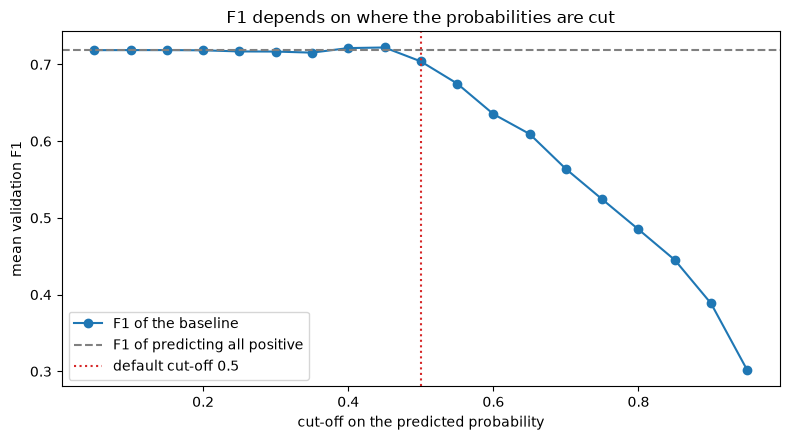

,F1,share predicted positive
threshold,,
0.05,0.7186,1.0000
0.10,0.7187,0.9998
0.15,0.7187,0.9998
0.20,0.7184,0.9990
0.25,0.7170,0.9961
0.30,0.7168,0.9879
0.35,0.7154,0.9480
0.40,0.7213,0.8270
0.45,0.7221,0.6443


In [10]:
# The baseline's validation probabilities, cut at every threshold from 0.05 to 0.95
thresholds = np.round(np.arange(0.05, 1.0, 0.05), 2)
by_threshold = pd.DataFrame([
    {"threshold": t,
     "F1": np.mean([f1_score(y, p >= t) for y, p in time_baseline.predictions]),
     "share predicted positive": np.mean([(p >= t).mean() for _, p in time_baseline.predictions])}
    for t in thresholds]).set_index("threshold")

best = by_threshold["F1"].idxmax()
print(f"F1 at 0.5: {by_threshold.loc[0.5, 'F1']:.4f}   best F1: {by_threshold['F1'].max():.4f} at {best}"
      f"   range over the cut-offs: {by_threshold['F1'].min():.4f} to {by_threshold['F1'].max():.4f}")
print(f"AP (one number, no cut-off): {time_baseline.ap.mean():.4f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(by_threshold.index, by_threshold["F1"], marker="o", label="F1 of the baseline")
ax.axhline(all_positive_f1.mean(), color="gray", linestyle="--", label="F1 of predicting all positive")
ax.axvline(0.5, color="tab:red", linestyle=":", label="default cut-off 0.5")
ax.set(xlabel="cut-off on the predicted probability", ylabel="mean validation F1",
       title="F1 depends on where the probabilities are cut")
ax.legend()
plt.tight_layout()
plt.show()

by_threshold.round(4)

**Conclusions:**
* **F1 depends heavily on the cut-off:** on the same probabilities of the same model it ranges from **0.30** (cut-off 0.95) to **0.72** (cut-off 0.45). Around the default 0.5 a step of 0.05 moves it by up to 0.03: 0.7221 at 0.45, 0.7040 at 0.50 and 0.6751 at 0.55.
* **Below a cut-off of 0.40 the model calls almost everyone a repeat buyer** (more than 83% of the rows), and F1 settles at the all-positive value of about 0.719. Even the best cut-off only reaches 0.7221, barely above predicting a repeat purchase for everyone.
* **So F1 at a fixed cut-off measures where the probabilities fall relative to 0.5 as much as how well the model separates the customers.** A treatment that only shifts the probabilities could gain or lose F1 without ranking anyone better.
* **Average precision decides the comparisons:** it reads the probabilities themselves, so it has no cut-off to depend on. F1 stays the competition metric: the cut-off is tuned on the validation splits for the final model, and that model's F1 is the number reported.

____________________________________________________________________________________________________

## 1.6. Missing Values Comparison and Selection

In [11]:
class ProportionalImputer:
    """Fill each missing label with one drawn from its column's training labels,
    in their training shares.

    scikit-learn has no such imputer, and `fill_missing` needs only `fit` and
    `transform`, so a short class is enough.
    """

    def __init__(self, random_state=None):
        self.random_state = random_state

    def fit(self, frame):
        self.shares = {c: frame[c].value_counts(normalize=True) for c in frame}
        return self

    def transform(self, frame):
        draws = np.random.default_rng(self.random_state)
        frame = frame.copy()
        for column, shares in self.shares.items():
            gaps = frame[column].isna()
            if gaps.any():
                frame.loc[gaps, column] = draws.choice(
                    shares.index, size=gaps.sum(), p=shares.to_numpy())
        return frame



### 1.6.1. Fill Plans

In this sub section we define the possible inputers as well as the plans. After defining we call on held_out_scores function 

In [ ]:
# One imputer per fill. "own level" gives a missing label a category of its
# own instead of the common one.
fills = {"median": SimpleImputer(strategy="median"),
         "mean": SimpleImputer(strategy="mean"),
         "zero": SimpleImputer(strategy="constant", fill_value=0),
         "mode": SimpleImputer(strategy="most_frequent"),
         "own level": SimpleImputer(strategy="constant", fill_value="(missing)"),
         "proportional": ProportionalImputer(random_state=RANDOM_STATE)}

plans = {
    "median / mode": [(numeric, fills["median"]), (categorical, fills["mode"])],
    "mean / mode": [(numeric, fills["mean"]), (categorical, fills["mode"])],
    "zero / mode": [(numeric, fills["zero"]), (categorical, fills["mode"])],
    "median / own level": [(numeric, fills["median"]), (categorical, fills["own level"])],
    "median / proportional": [(numeric, fills["median"]), (categorical, fills["proportional"])],
}

plan_scores = {name: held_out_scores(partial(fill_missing, plan=plan),
                                 frame, time_splits, numeric, categorical)
               for name, plan in plans.items()}


def fill_with_indicator(train, test, plan):
    """Mark where spend_365d was missing in its own 0/1 column, then fill."""
    train, test = (f.assign(spend_365d_missing=f["spend_365d"].isna().astype(int))
                   for f in (train, test))
    return fill_missing(train, test, plan)


# The indicator arm adds a column, so its scorer needs the longer numeric list
plan_scores["median + indicator / mode"] = held_out_scores(
    partial(fill_with_indicator, plan=plans["median / mode"]),
    frame, time_splits, numeric + ["spend_365d_missing"], categorical)

plan_board = pd.DataFrame({
    "AP": {k: v.ap.mean() for k, v in plan_scores.items()},
    "AP SEM": {k: sem(v.ap) for k, v in plan_scores.items()},
    "F1": {k: v.f1.mean() for k, v in plan_scores.items()},
})
print(plan_board.round(4).to_string())

                               AP  AP SEM      F1
median / mode              0.7853  0.0090  0.7040
mean / mode                0.7842  0.0090  0.7043
zero / mode                0.7839  0.0084  0.7030
median / own level         0.7847  0.0093  0.7101
median / proportional      0.7853  0.0091  0.7053
median + indicator / mode  0.7865  0.0091  0.7050


### 1.6.2. Paired Comparison

In [13]:
shipped = plan_scores["median / mode"]

# Paired: each arm minus the shipped arm on the SAME split, so the noise they
# share cancels and what is left is the difference between the arms.
paired = pd.DataFrame({
    name: {"dAP": (run.ap - shipped.ap).mean(),
           "AP SEM": sem(run.ap - shipped.ap),
           "better on": f"{int((run.ap > shipped.ap).sum())} of {len(run.ap)}",
           "dF1": (run.f1 - shipped.f1).mean()}
    for name, run in plan_scores.items() if name != "median / mode"}).T
print(paired.to_string())

                                dAP    AP SEM better on       dF1
mean / mode               -0.001126  0.000571    2 of 7  0.000319
zero / mode               -0.001411  0.000899    4 of 7 -0.000987
median / own level        -0.000578  0.001284    3 of 7  0.006097
median / proportional     -0.000014  0.001177    3 of 7  0.001345
median + indicator / mode  0.001163  0.000972    5 of 7   0.00103


### 1.6.3. Final Imputation
The plans above all fill the gaps. The last comparison asks whether filling is better than simply dropping the training rows that carry a missing value. Rows are dropped from the training half only, so both options are scored on the same untouched validation rows.

In [ ]:
def drop_incomplete(train, test, plan):
    """Drop the training rows carrying any missing value, then fill what the rest need."""
    complete = ~train.isna().any(axis=1)
    return fill_missing(train[complete], test, plan)
 

keep_rows = plan_scores["median / mode"]
drop_rows = held_out_scores(partial(drop_incomplete, plan=plans["median / mode"]),
                            frame, time_splits, numeric, categorical)
paired = keep_rows.ap - drop_rows.ap

print(f"impute the missing values  n={len(frame):,}   AP {keep_rows.ap.mean():.4f}   F1 {keep_rows.f1.mean():.4f}")
print(f"drop the rows    n={(~frame.isna().any(axis=1)).sum():,}"
      f"   AP {drop_rows.ap.mean():.4f}   F1 {drop_rows.f1.mean():.4f}")
print(f"paired AP difference {paired.mean():+.4f}"
      f" +/- {sem(paired):.4f}"
      f"   imputing wins on {(paired > 0).sum()} of {len(paired)} splits")

impute the missing values  n=6,469   AP 0.7853   F1 0.7040
drop the rows    n=3,646   AP 0.7770   F1 0.6784
paired AP difference +0.0083 +/- 0.0025   imputing wins on 7 of 7 splits


In [15]:
# The fill plan this section chose
chosen = "median / mode"

**Conclusions:**
* **No fill plan beats `median / mode` by more than two paired standard errors in AP.** The largest gain is `median + indicator / mode` (+0.0012 ± 0.0010, better on 5 of 7 splits), within noise; `median / proportional` (−0.0000 ± 0.0012) and `median / own level` (−0.0006 ± 0.0013) are level with it, and `zero / mode` (−0.0014 ± 0.0009) and `mean / mode` (−0.0011 ± 0.0006, better on only 2 of 7) are, if anything, slightly worse.
* **F1 would have told a different story, which is why it does not decide:** `median / own level` gains +0.0061 in F1 but loses 0.0006 in AP. Its F1 gain comes from shifting the probabilities around the 0.5 cut-off, not from ranking the customers better (section 1.5.3).
* **The differences are small** because only `spend_365d` has numeric gaps (3.2%), so the numeric fill changes a single column. The missingness indicator does not pay for its extra column, which matches section 1.4: a missing `spend_365d` barely changes the repeat rate (0.552 against 0.560).
* **Filling is clearly better than dropping:** dropping the incomplete training rows keeps only 3,646 of the 6,469 rows (44% lost, mostly because of `city`) and scores AP 0.7770 against 0.7853, a paired difference of **+0.0083 ± 0.0025** in favour of filling, ahead on all 7 splits.
* **The recipe keeps `median / mode`**, the simplest plan: it adds no random draws and no extra columns, and no alternative earns its extra complexity. `KNN` and `iterative` imputation were not scored: only one numeric column has gaps, and in the course practical they brought no gain over the median.

____________________________________________________________________________________________________

## 1.7. Outliers

### 1.7.1. Outlier Detection
An outlier here is a **real value far from the rest**, such as a very large purchase, not an error: impossible values are a different problem with their own rules. This step only **looks** at the full table to decide which columns need a treatment; it fits nothing that the model uses, so it cannot leak. The treatments themselves are compared in 1.7.2, inside each split.

`outside_fences` (from the course practical) marks a row when at least one of its columns falls beyond the fences: 1.5 × IQR beyond the quartiles, or 3 standard deviations from the mean (`ddof=0`, the population convention). A missing value counts as **inside**, so a treatment can run before the fill without calling every row with a gap an outlier.

In [ ]:
import pandas as pd

# 1. Load the dataset from the previous stage
inputFile = "/Users/renata/Library/CloudStorage/OneDrive-NOVAIMS/mestrado/1semestre/AprendizagemAutomatica(S1)/ProjectML/ML_Grupo18/data/trainDataset/train_2_5_1.csv"
df_clean = pd.read_csv(inputFile)


# 2. Define the fence check function
def outside_fences(frame, columns, rule="iqr", k=1.5):
  """True for rows with a named column beyond its fences.

  `rule="iqr"` draws the fences k IQRs beyond the quartiles, `rule="zscore"` k
  standard deviations from the mean. A missing value counts as INSIDE: a
  comparison with a missing value is False both ways, so without the `isna()`
  term every row carrying one would be called an outlier.
  """
  values = frame[columns]
  if rule == "iqr":
    q1, q3 = values.quantile(0.25), values.quantile(0.75)
    low, high = q1 - k * (q3 - q1), q3 + k * (q3 - q1)
  else:
    mean, sd = values.mean(), values.std(ddof=0)
    low, high = mean - k * sd, mean + k * sd
  within = values.ge(low) & values.le(high)
  return ~(within | values.isna()).all(axis=1)


# 3. Define the numeric columns to inspect
cols_to_analyze = [
    'prior_total_spend',
    'prior_purchase_count',
    'prior_mean_purchase_value',
    'spend_365d',
]

# 4. Compute the outlier mask using the defined function
outlier_mask = outside_fences(
    df_clean, columns=cols_to_analyze, rule='iqr', k=1.5
)

# 5. Print the outlier detection summary
print("=== OUTLIER DETECTION SUMMARY ===")
print(f"• Total rows in dataset: {len(df_clean)}")
print(
    "• Rows with at least one outlier:"
    f" {outlier_mask.sum()} ({outlier_mask.sum()/len(df_clean)*100:.2f}%)"
)
print(
    "• Normal rows (without outliers):"
    f" {(~outlier_mask).sum()} ({(~outlier_mask).sum()/len(df_clean)*100:.2f}%)"
)

# 6. Inspect sample rows identified as outliers
print("\n--- Sample Rows Identified as Outliers ---")
print(df_clean[outlier_mask][cols_to_analyze].head())

In [17]:
# Outliers only make sense on measures (amounts, counts, days). Flags, calendar
# parts and years are numbers that name a category, so they are left out.
labels_as_numbers = ["is_first_purchase", "is_weekend", "since_2015_or_earlier",
                     "purchase_year", "purchase_quarter", "purchase_month", "purchase_day",
                     "purchase_dayofweek", "customer_since_year"]
measures = [c for c in numeric if c not in labels_as_numbers]
print(f"{len(measures)} measures out of {len(numeric)} numeric columns")

28 measures out of 37 numeric columns


In [18]:
# Per measure: how skewed it is, whether its box has zero width, and how many
# values fall beyond each rule's fences
values = frame[measures]
q1, q3 = values.quantile(0.25), values.quantile(0.75)
iqr = q3 - q1
z = (values - values.mean()) / values.std(ddof=0)
pd.DataFrame({
    "skew": values.skew(),
    "IQR = 0": iqr.eq(0),
    "% beyond IQR fences": ((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)).mean() * 100,
    "% beyond |z| > 3": (z.abs() > 3).mean() * 100,
    "max": values.max(),
}).sort_values("% beyond IQR fences", ascending=False).round(2)

,skew,IQR = 0,% beyond IQR fences,% beyond |z| > 3,max
spend_30d,5.50,False,16.39,2.07,2.229721e+04
Total Portes,19.55,True,16.28,0.54,1.810600e+02
Total Desc_ Linha,5.92,False,12.71,2.27,4.103440e+03
prior_min_purchase_value,6.15,False,11.73,2.10,6.298980e+03
purchase_count_180d,3.22,False,11.39,3.48,3.700000e+01
spend_90d,3.72,False,10.22,2.09,3.023488e+04
prior_total_spend,3.08,False,9.92,2.88,2.478651e+05
Total a Pagar,4.21,False,9.15,2.13,2.229721e+04
Total Liquido,4.15,False,9.07,2.10,1.812781e+04
Total Bruto,4.31,False,9.03,1.99,2.157828e+04


In [19]:
# Both rules across every measure: a row is an outlier when any measure is beyond its fences
for rule, k in [("iqr", 1.5), ("zscore", 3)]:
    kept = ~outside_fences(frame, measures, rule, k=k)
    print(f"{rule} (k={k}): rows kept {kept.sum():,} of {len(frame):,}"
          f"  ({100 * (1 - kept.mean()):.2f}% removed)")
    print(f"   repeat rate  {frame[target].mean():.4f} -> {frame.loc[kept, target].mean():.4f}"
          f"   among the rows the rule DELETES: {frame.loc[~kept, target].mean():.4f}")

iqr (k=1.5): rows kept 2,130 of 6,469  (67.07% removed)
   repeat rate  0.5597 -> 0.4723   among the rows the rule DELETES: 0.6027
zscore (k=3): rows kept 4,826 of 6,469  (25.40% removed)
   repeat rate  0.5597 -> 0.5197   among the rows the rule DELETES: 0.6774


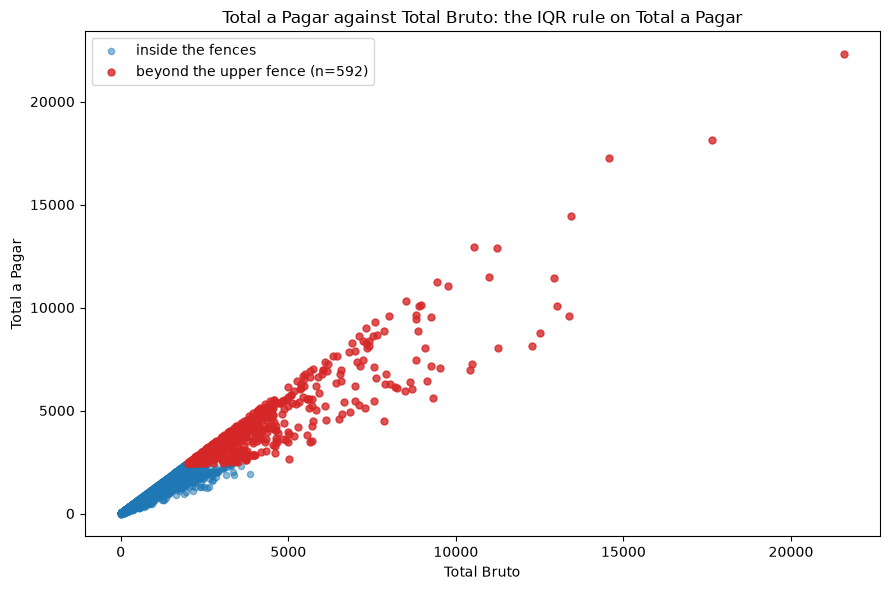

In [20]:
# What the IQR rule calls an outlier on the invoice total: the large purchases
# sit on the same line as the rest, so they are big orders, not broken records
x_feature, y_feature = "Total Bruto", "Total a Pagar"
q1, q3 = frame[y_feature].quantile([0.25, 0.75])
is_outlier = frame[y_feature] > q3 + 1.5 * (q3 - q1)

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(frame.loc[~is_outlier, x_feature], frame.loc[~is_outlier, y_feature],
           alpha=0.5, s=20, label="inside the fences")
ax.scatter(frame.loc[is_outlier, x_feature], frame.loc[is_outlier, y_feature],
           alpha=0.8, s=25, color="tab:red", label=f"beyond the upper fence (n={is_outlier.sum()})")
ax.set(xlabel=x_feature, ylabel=y_feature, title=f"{y_feature} against {x_feature}: the IQR rule on {y_feature}")
ax.legend()
plt.tight_layout()
plt.show()

**Conclusions:**
* **Every measure has a long right tail.** 27 of the 28 measures have a skewness between 2 and 27; only `customer_tenure_days` is close to symmetric (0.63). Between 4% and 16% of each measure's values fall beyond its IQR fences.
* **The 1.5 × IQR rule fails as a detector:** applied across all measures it removes **67.07%** of the rows (2,130 kept of 6,469), close to the 67.33% the course practical found on its own data. A rule that calls two thirds of the data anomalous has not found anomalies.
* **And it is not neutral:** the repeat rate falls from **0.560 to 0.472** in the rows it keeps, while the rows it deletes repeat at **0.603**. Customers who buy more have the largest values, so deleting extreme rows deletes the customers who come back, which is the signal the model needs. The |z| > 3 rule is milder (25.40% removed) but has the same bias (0.677 among the deleted rows).
* **Three measures have a box of zero width** (`Total Portes`, `Total Desc_ Global`, `invoice_count_current_purchase`): more than three quarters of their values are equal, so every other value is beyond the fences. Any fence-based treatment would erase what little those columns carry.
* **`spend_365d` and `prior_mean_purchase_value` reach 1,000,000,000.** That is an error code, not an outlier, and it is what drives their skewness of about 20; it calls for its own treatment as an impossible value.
* **The extreme invoices are real:** in the scatter plot the values beyond the upper fence of `Total a Pagar` lie on the same line as the rest, so they are large orders, not broken records. Section 1.7.2 therefore compares treatments that keep these rows (clipping, compressing the tail) against the one that deletes them.

### 1.7.2. Outlier Treatment

**Conclusions:**

____________________________________________________________________________________________________

## 1.8. Encoding and Scaling

### 1.8.1. Encoding

### 1.8.2. Scaling

**Conclusions:**